In [1]:
import os, glob, math, random, xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
import os, gc, time


DATA_ROOT = "/kaggle/input/competitions/2026task3/detection"
TRAIN_IMG_DIR = os.path.join(DATA_ROOT, "train")
XML_DIR = os.path.join(DATA_ROOT, "train_location")
TEST_IMG_DIR = os.path.join(DATA_ROOT, "test")
GT_CSV = os.path.join(DATA_ROOT, "fovea_localization_train_GT.csv")
SAMPLE_SUB = os.path.join(DATA_ROOT, "sample_submission.csv")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [2]:
def load_gt():
    df = pd.read_csv(GT_CSV)
    # data 列可能是 1,2,3... 对应 0001.jpg
    df["stem"] = df["data"].apply(lambda x: f"{int(x):04d}")
    return df.set_index("stem")

def load_bbox(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find("size")
    w = int(size.find("width").text); h = int(size.find("height").text)
    obj = root.find("object")
    if obj is None:
        return None, (w, h)
    bb = obj.find("bndbox")
    box = [float(bb.find("xmin").text), float(bb.find("ymin").text),
           float(bb.find("xmax").text), float(bb.find("ymax").text)]
    return box, (w, h)

gt = load_gt()
records = []
for stem in gt.index:
    xml_path = os.path.join(XML_DIR, f"{stem}.xml")
    img_path = os.path.join(TRAIN_IMG_DIR, f"{stem}.jpg")
    box, (w, h) = load_bbox(xml_path)
    fx, fy = gt.loc[stem, "Fovea_X"], gt.loc[stem, "Fovea_Y"]
    records.append(dict(stem=stem, img=img_path, box=box, W=w, H=h, fx=fx, fy=fy))
train_df = pd.DataFrame(records)
print(train_df.head())
print("样本数:", len(train_df))

   stem                                                img  \
0  0001  /kaggle/input/competitions/2026task3/detection...   
1  0002  /kaggle/input/competitions/2026task3/detection...   
2  0003  /kaggle/input/competitions/2026task3/detection...   
3  0004  /kaggle/input/competitions/2026task3/detection...   
4  0005  /kaggle/input/competitions/2026task3/detection...   

                                box     W     H           fx           fy  
0     [631.0, 903.0, 839.0, 1121.0]  1956  1934   734.031331  1016.817066  
1     [653.0, 901.0, 883.0, 1131.0]  1956  1934   769.024859  1018.059762  
2   [1368.0, 939.0, 1570.0, 1137.0]  2992  2000  1470.287475  1037.601074  
3  [1560.0, 1006.0, 1757.0, 1202.0]  2992  2000  1658.316671  1104.020062  
4  [1637.0, 1016.0, 1826.0, 1202.0]  2992  2000  1729.828431  1107.209978  
样本数: 80


In [3]:
train_df["cx"] = train_df["box"].apply(lambda b: (b[0]+b[2])/2)
train_df["cy"] = train_df["box"].apply(lambda b: (b[1]+b[3])/2)
train_df["dX"] = train_df["cx"] - train_df["fx"]
train_df["dY"] = train_df["cy"] - train_df["fy"]

print("ΔX  mean/std/max|.|:", train_df.dX.mean(), train_df.dX.std(), train_df.dX.abs().max())
print("ΔY  mean/std/max|.|:", train_df.dY.mean(), train_df.dY.std(), train_df.dY.abs().max())

# 全可见假设下，直接用 bbox 中心当坐标的 RMSE：
errs = np.concatenate([train_df.dX.values, train_df.dY.values])
rmse_center = np.sqrt(np.mean(errs**2))
print("bbox中心直接当坐标的训练RMSE:", rmse_center)

ΔX  mean/std/max|.|: 0.6068742500000113 1.3175620458223454 4.144571000000042
ΔY  mean/std/max|.|: 1.3160458750000033 1.8635619992075025 5.007329999999911
bbox中心直接当坐标的训练RMSE: 1.9031547173746677


In [4]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMG_SIZE = 800

def get_train_transform():
    return A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.Rotate(limit=15, p=0.5),
        A.RandomBrightnessContrast(p=0.3),
        A.ColorJitter(p=0.3),
        A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
        ToTensorV2(),
    ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels'], min_visibility=0.5))

def get_val_transform():
    return A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
        ToTensorV2(),
    ])

class FoveaDetDataset(Dataset):
    def __init__(self, df, train=True):
        self.df = df.reset_index(drop=True)
        self.train = train
        self.tf = get_train_transform() if train else get_val_transform()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = np.array(Image.open(r.img).convert("RGB"))
        if self.train:
            out = self.tf(image=img, bboxes=[r.box], labels=[1])
            boxes = torch.tensor(out['bboxes'], dtype=torch.float32)
        else:
            out = self.tf(image=img)
            sx, sy = IMG_SIZE / r.W, IMG_SIZE / r.H
            boxes = torch.tensor([[r.box[0]*sx, r.box[1]*sy, r.box[2]*sx, r.box[3]*sy]], dtype=torch.float32)
        target = {"boxes": boxes, "labels": torch.tensor([1], dtype=torch.int64)}
        return out['image'], target, torch.tensor([r.W, r.H], dtype=torch.float32)

In [5]:
def build_model():
    weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    model = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.05)
    in_feat = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)

    # 冻结 backbone 前两个 stage，减少小数据过拟合
    for name, param in model.backbone.body.named_parameters():
        if 'layer1' in name or 'layer2' in name:
            param.requires_grad = False
    return model

In [6]:
def collate_fn(batch):
    imgs, tgts, sizes = zip(*batch)
    return list(imgs), list(tgts), list(sizes)

def train_one_epoch(model, loader, opt, epoch=None, fold=None):
    model.train()
    total = 0
    pbar = tqdm(loader, desc=f"fold{fold} ep{epoch}", leave=False)
    for imgs, tgts, _ in pbar:
        imgs = [im.to(DEVICE) for im in imgs]
        tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
        loss_dict = model(imgs, tgts)
        loss = sum(loss_dict.values())
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        total += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}")
    return total / len(loader)

@torch.no_grad()
def eval_center_rmse(model, df):
    """全可见假设下，bbox中心当坐标的 RMSE（原图尺度），使用无增强 transform"""
    model.eval()
    errs = []
    for _, r in df.iterrows():
        img = np.array(Image.open(r.img).convert("RGB"))
        t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
        out = model(t)[0]
        if len(out["boxes"]) == 0:
            errs += [r.W, r.H]
            continue
        b = out["boxes"][out["scores"].argmax()].cpu().numpy()
        cx = (b[0]+b[2])/2 / IMG_SIZE * r.W
        cy = (b[1]+b[3])/2 / IMG_SIZE * r.H
        errs += [cx - r.fx, cy - r.fy]
    return float(np.sqrt(np.mean(np.square(errs))))

def run_kfold(n_splits=5, epochs=25, bs=8, lr=1e-4):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof_rmse = []
    fold_models = []
    for fold, (tr, va) in enumerate(kf.split(train_df)):
        tr_df, va_df = train_df.iloc[tr], train_df.iloc[va]
        ds_tr = FoveaDetDataset(tr_df, train=True)
        dl_tr = DataLoader(ds_tr, batch_size=bs, shuffle=True,
                           collate_fn=collate_fn, num_workers=0)
        model = build_model().to(DEVICE)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

        best_rmse = float('inf')
        best_state = None

        for ep in range(epochs):
            tl = train_one_epoch(model, dl_tr, opt, epoch=ep+1, fold=fold)
            scheduler.step()
            r = eval_center_rmse(model, va_df)
            if r < best_rmse:
                best_rmse = r
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                print(f"fold{fold} ep{ep+1} loss={tl:.3f} val_rmse={r:.2f}  <== NEW BEST", flush=True)
            else:
                print(f"fold{fold} ep{ep+1} loss={tl:.3f} val_rmse={r:.2f}", flush=True)

        model.load_state_dict(best_state)
        model.to(DEVICE)
        torch.save(best_state, f"/kaggle/working/fold{fold}.pth")
        oof_rmse.append(best_rmse)
        fold_models.append(model)
        print(f"== fold{fold} BEST val_rmse={best_rmse:.2f} saved ==", flush=True)

    print("OOF RMSE:", np.mean(oof_rmse), oof_rmse)
    return fold_models

fold_models = run_kfold()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 205MB/s]


fold0 ep1:   0%|          | 0/8 [00:00<?, ?it/s]

fold0 ep1 loss=0.327 val_rmse=636.97  <== NEW BEST


fold0 ep2:   0%|          | 0/8 [00:00<?, ?it/s]

fold0 ep2 loss=0.111 val_rmse=15.97  <== NEW BEST


... (242 outputs left out)

fold4 ep24:   0%|          | 0/8 [00:00<?, ?it/s]

fold4 ep24 loss=0.032 val_rmse=636.78


fold4 ep25:   0%|          | 0/8 [00:00<?, ?it/s]

fold4 ep25 loss=0.030 val_rmse=636.78
== fold4 BEST val_rmse=111.81 saved ==
OOF RMSE: 33.0013204574585 [14.096423149108887, 12.447797775268555, 4.503339767456055, 22.145648956298828, 111.81339263916016]


In [7]:
@torch.no_grad()
def predict_one(model, img_path):
    img = np.array(Image.open(img_path).convert("RGB"))
    h, w = img.shape[:2]
    t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
    out = model(t)[0]
    if len(out["boxes"]) == 0:
        return None, 0.0
    idx = out["scores"].argmax()
    b = out["boxes"][idx].cpu().numpy()
    score = float(out["scores"][idx].cpu())
    cx = (b[0]+b[2])/2 / IMG_SIZE * w
    cy = (b[1]+b[3])/2 / IMG_SIZE * h
    return (cx, cy), score

def ensemble_predict(models, img_path):
    preds, scores = [], []
    for m in models:
        m.eval()
        p, s = predict_one(m, img_path)
        if p is not None:
            preds.append(p); scores.append(s)
    if not preds:
        return (0.0, 0.0), 0.0
    return tuple(np.mean(preds, axis=0)), float(np.mean(scores))

def make_submission(models, tau=0.5, out="submission.csv"):
    test_imgs = sorted(glob.glob(os.path.join(TEST_IMG_DIR, "*.jpg")))
    rows = []
    for p in test_imgs:
        stem = os.path.splitext(os.path.basename(p))[0]   # 0081
        num = int(stem)                                    # 81
        (cx, cy), score = ensemble_predict(models, p)
        if score < tau:
            cx, cy = 0.0, 0.0
        rows.append((f"{num}_Fovea_X", cx))
        rows.append((f"{num}_Fovea_Y", cy))
    sub = pd.DataFrame(rows, columns=["ImageID", "value"])
    # 严格按 sample_submission 顺序对齐
    ss = pd.read_csv(SAMPLE_SUB)
    ss = ss.set_index("ImageID").join(sub.set_index("ImageID"))
    ss["value"] = ss["value"].fillna(0.0)
    ss.reset_index().to_csv(out, index=False)
    print("saved", out)
    return sub

# 先看测试集 score 分布，辅助定 tau
def score_distribution(models):
    test_imgs = sorted(glob.glob(os.path.join(TEST_IMG_DIR, "*.jpg")))
    ss = []
    for p in tqdm(test_imgs, desc="scoring test"):
        _, s = ensemble_predict(models, p)
        ss.append((os.path.basename(p), s))
    df = pd.DataFrame(ss, columns=["file","score"]).sort_values("score")
    print(df.to_string(index=False))
    return df

sd = score_distribution(fold_models)

scoring test:   0%|          | 0/20 [00:00<?, ?it/s]

    file    score
0081.jpg 0.799565
0086.jpg 0.850491
0091.jpg 0.907322
0096.jpg 0.946879
0084.jpg 0.962000
0092.jpg 0.969022
0093.jpg 0.973396
0099.jpg 0.975521
0095.jpg 0.976144
0094.jpg 0.977479
0082.jpg 0.978043
0088.jpg 0.978321
0090.jpg 0.978559
0097.jpg 0.980797
0087.jpg 0.981279
0085.jpg 0.981371
0083.jpg 0.982225
0098.jpg 0.982939
0100.jpg 0.983337
0089.jpg 0.984133


In [8]:
import numpy as np
from PIL import Image
import torch

@torch.no_grad()
def collect_train_scores(models, df):
    """在训练集上跑 5 折 ensemble，收集每张图的最大 score"""
    scores = []
    for _, r in df.iterrows():
        img = np.array(Image.open(r.img).convert("RGB"))
        t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
        fold_scores = []
        for m in models:
            m.eval()
            out = m(t)[0]
            if len(out["scores"]) > 0:
                fold_scores.append(float(out["scores"].max()))
        if fold_scores:
            scores.append(np.mean(fold_scores))
    return np.array(scores)

train_scores = collect_train_scores(fold_models, train_df)
print("训练集 score 统计：")
print(f"  min={train_scores.min():.3f}")
print(f"  5% 分位={np.percentile(train_scores, 5):.3f}")
print(f"  10% 分位={np.percentile(train_scores, 10):.3f}")
print(f"  中位数={np.median(train_scores):.3f}")
print(f"  max={train_scores.max():.3f}")

tau_recommended = np.percentile(train_scores, 5)
print(f"\n推荐 tau = {tau_recommended:.3f}")

训练集 score 统计：
  min=0.713
  5% 分位=0.927
  10% 分位=0.963
  中位数=0.980
  max=0.985

推荐 tau = 0.927


In [9]:
@torch.no_grad()
def ensemble_predict_fast(models, img_path):
    img = np.array(Image.open(img_path).convert("RGB"))
    h, w = img.shape[:2]
    t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
    preds, scores = [], []
    for m in models:
        m.eval()
        out = m(t)[0]
        if len(out["boxes"]) == 0:
            continue
        idx = out["scores"].argmax()
        b = out["boxes"][idx].cpu().numpy()
        preds.append(((b[0]+b[2])/2 / IMG_SIZE * w, (b[1]+b[3])/2 / IMG_SIZE * h))
        scores.append(float(out["scores"][idx].cpu()))
    if not preds:
        return (0.0, 0.0), 0.0
    return tuple(np.mean(preds, axis=0)), float(np.mean(scores))

def make_submission(models, tau=0.0, out="submission.csv"):
    test_imgs = sorted(glob.glob(os.path.join(TEST_IMG_DIR, "*.jpg")))
    assert len(test_imgs) > 0, "测试图没找到，检查 TEST_IMG_DIR"
    rows = []
    for p in test_imgs:
        stem = os.path.splitext(os.path.basename(p))[0]
        num = int(stem)
        (cx, cy), score = ensemble_predict_fast(models, p)
        if score < tau:
            cx, cy = 0.0, 0.0
        rows.append((f"{num}_Fovea_X", cx))
        rows.append((f"{num}_Fovea_Y", cy))
        print(f"{stem}: score={score:.3f} pred=({cx:.1f},{cy:.1f})", flush=True)

    sub = pd.DataFrame(rows, columns=["ImageID", "value"])
    ss = pd.read_csv(SAMPLE_SUB)[["ImageID"]]
    ss = ss.merge(sub, on="ImageID", how="left")
    ss["value"] = ss["value"].fillna(0.0)
    ss.to_csv(out, index=False)

    assert os.path.exists(out), "文件未生成"
    check = pd.read_csv(out)
    print("=== 生成成功 ===")
    print("路径:", os.path.abspath(out))
    print("行数:", len(check), "(应为 40)")
    print("空值:", check["value"].isna().sum(), "(应为 0)")
    print(check.head(6))
    return check

# 先确保 fold_models 存在
print("模型数:", len(fold_models))

# 生成提交（tau=0.15，只防御极端低分图，当前测试集不会误伤）
check = make_submission(fold_models, tau=0.15, out="submission.csv")

模型数: 5
0081: score=0.800 pred=(1682.1,1133.6)
0082: score=0.978 pred=(1685.7,1106.4)
0083: score=0.982 pred=(1487.8,1046.2)
0084: score=0.962 pred=(1235.1,1116.4)
0085: score=0.981 pred=(1199.7,980.4)
0086: score=0.850 pred=(1253.7,1133.7)
0087: score=0.981 pred=(1465.9,1022.5)
0088: score=0.978 pred=(1253.2,1121.5)
0089: score=0.984 pred=(1476.7,1052.3)
0090: score=0.979 pred=(1666.4,1094.3)
0091: score=0.907 pred=(1489.2,1044.7)
0092: score=0.969 pred=(1710.5,1106.0)
0093: score=0.973 pred=(1692.9,1166.0)
0094: score=0.977 pred=(1440.3,1028.4)
0095: score=0.976 pred=(1679.9,1102.5)
0096: score=0.947 pred=(1709.0,1074.7)
0097: score=0.981 pred=(1497.0,1215.9)
0098: score=0.983 pred=(1474.2,1071.5)
0099: score=0.976 pred=(1451.4,1037.6)
0100: score=0.983 pred=(1679.7,1092.8)
=== 生成成功 ===
路径: /kaggle/working/submission.csv
行数: 40 (应为 40)
空值: 0 (应为 0)
      ImageID      value
0  81_Fovea_X  1682.1448
1  81_Fovea_Y  1133.5823
2  82_Fovea_X  1685.6746
3  82_Fovea_Y  1106.4250
4  83_Fovea_X

In [10]:
# 跑完训练后，加这段
@torch.no_grad()
def find_hard_samples(models, df):
    """找每折验证集里误差最大的样本"""
    results = []
    for fold, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(train_df)):
        va_df = train_df.iloc[va]
        m = models[fold]
        for _, r in va_df.iterrows():
            img = np.array(Image.open(r.img).convert("RGB"))
            t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
            out = m(t)[0]
            if len(out["boxes"]) == 0:
                err = 9999
            else:
                b = out["boxes"][out["scores"].argmax()].cpu().numpy()
                cx = (b[0]+b[2])/2 / IMG_SIZE * r.W
                cy = (b[1]+b[3])/2 / IMG_SIZE * r.H
                err = np.sqrt((cx - r.fx)**2 + (cy - r.fy)**2)
            results.append((r.stem, err, r.img))
    results.sort(key=lambda x: -x[1])
    print("误差最大的 5 张训练图：")
    for stem, err, path in results[:5]:
        print(f"  {stem}: {err:.1f} px  {path}")
    return results

hard = find_hard_samples(fold_models, train_df)

误差最大的 5 张训练图：
  0072: 614.5 px  /kaggle/input/competitions/2026task3/detection/train/0072.jpg
  0070: 99.4 px  /kaggle/input/competitions/2026task3/detection/train/0070.jpg
  0024: 93.7 px  /kaggle/input/competitions/2026task3/detection/train/0024.jpg
  0049: 76.8 px  /kaggle/input/competitions/2026task3/detection/train/0049.jpg
  0044: 70.3 px  /kaggle/input/competitions/2026task3/detection/train/0044.jpg


In [11]:
import torch
print("GPU 数量:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i), 
          f"{torch.cuda.get_device_properties(i).total_memory/1e9:.1f} GB")

GPU 数量: 2
0 Tesla T4 15.6 GB
1 Tesla T4 15.6 GB


In [12]:
import os, gc, json, time
import numpy as np, pandas as pd, torch
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold

# 这个函数在子进程里跑，必须把用到的都放进来或全局可见
def train_one_fold(fold, tr_idx, va_idx, config, gpu_id, save_dir):
    os.environ["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    import torch
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

    # 用全局的 train_df / 类 / 函数（notebook 里 fork 模式下可访问）
    tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
    va_df = train_df.iloc[va_idx].reset_index(drop=True)

    ds_tr = FoveaDetDataset(tr_df, train=config["use_aug"])
    dl_tr = DataLoader(ds_tr, batch_size=config["bs"], shuffle=True,
                       collate_fn=collate_fn, num_workers=0)
    model = build_model(freeze=config["freeze"]).to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=config["lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=config["epochs"])

    best, best_state, history = float("inf"), None, []
    for ep in range(config["epochs"]):
        model.train()
        total = 0
        for imgs, tgts, _ in dl_tr:
            imgs = [im.to(device) for im in imgs]
            tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
            loss = sum(model(imgs, tgts).values())
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); total += loss.item()
        sched.step()

        # 评估（用无增强 transform）
        model.eval()
        errs = []
        with torch.no_grad():
            for _, r in va_df.iterrows():
                img = np.array(Image.open(r.img).convert("RGB"))
                t = get_val_transform()(image=img)['image'].unsqueeze(0).to(device)
                out = model(t)[0]
                if len(out["boxes"]) == 0:
                    errs += [r.W, r.H]; continue
                b = out["boxes"][out["scores"].argmax()].cpu().numpy()
                cx = (b[0]+b[2])/2 / IMG_SIZE * r.W
                cy = (b[1]+b[3])/2 / IMG_SIZE * r.H
                errs += [cx - r.fx, cy - r.fy]
        rmse = float(np.sqrt(np.mean(np.square(errs))))
        history.append(rmse)
        if rmse < best:
            best = rmse
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    path = os.path.join(save_dir, f"{config['name']}_fold{fold}.pth")
    torch.save(best_state, path)
    del model; gc.collect(); torch.cuda.empty_cache()
    return {"config": config["name"], "fold": fold, "best_rmse": best,
            "history": history, "ckpt": path}

In [13]:
def build_model(freeze=True):
    from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    model = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT, box_score_thresh=0.05)
    in_feat = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
    if freeze:
        for name, p in model.backbone.body.named_parameters():
            if 'layer1' in name or 'layer2' in name:
                p.requires_grad = False
    return model

In [14]:
SAVE_DIR = "/kaggle/working/exp"
os.makedirs(SAVE_DIR, exist_ok=True)

def run_all_serial(experiments, folds, save_dir):
    """串行跑所有 (experiment, fold)，单卡 gpu_id=0，不会卡"""
    results = []
    total = len(experiments) * len(folds)
    idx = 0
    for exp in experiments:
        for fold, (tr, va) in enumerate(folds):
            idx += 1
            print(f"[{idx}/{total}] {exp['name']} fold{fold} 开始", flush=True)
            t0 = time.time()
            r = train_one_fold(fold, tr, va, exp, gpu_id=0, save_dir=save_dir)
            print(f"[{idx}/{total}] {exp['name']} fold{fold} "
                  f"best_rmse={r['best_rmse']:.2f} 耗时{time.time()-t0:.0f}s", flush=True)
            results.append(r)
    return results

In [15]:
import time
from sklearn.model_selection import KFold

# ---------- 补上 FOLDS 定义 ----------
FOLDS = list(KFold(5, shuffle=True, random_state=42).split(train_df))

# ---------- 配置：精简版，3 组 × 3 折，~70 分钟 ----------
EXPERIMENTS_SMALL = [
    {"name": "E1_noaug",      "use_aug": False, "freeze": False, "bs": 4, "epochs": 10, "lr": 1e-4},
    {"name": "E2_aug",        "use_aug": True,  "freeze": False, "bs": 4, "epochs": 10, "lr": 1e-4},
    {"name": "E3_aug_freeze", "use_aug": True,  "freeze": True,  "bs": 4, "epochs": 10, "lr": 1e-4},
]

FOLDS_SMALL = FOLDS[:3]

t0 = time.time()
results = run_all_serial(EXPERIMENTS_SMALL, FOLDS_SMALL, SAVE_DIR)
print(f"\n总耗时 {time.time()-t0:.1f}s")

# ---------- 汇总成表 ----------
df_res = pd.DataFrame([
    {"exp": r["config"], "fold": r["fold"], "best_rmse": r["best_rmse"]}
    for r in results
])
pivot = df_res.pivot_table(index="exp", columns="fold", values="best_rmse")
pivot["OOF"] = df_res.groupby("exp")["best_rmse"].mean()
print("\n=== 对照实验汇总 ===")
print(pivot.round(2))

df_res.to_csv("/kaggle/working/exp_results.csv", index=False)
pivot.to_csv("/kaggle/working/exp_pivot.csv")
print("\n已保存 exp_results.csv / exp_pivot.csv")

[1/9] E1_noaug fold0 开始
[1/9] E1_noaug fold0 best_rmse=13.78 耗时246s
[2/9] E1_noaug fold1 开始
[2/9] E1_noaug fold1 best_rmse=63.24 耗时250s
[3/9] E1_noaug fold2 开始
[3/9] E1_noaug fold2 best_rmse=5.74 耗时245s
[4/9] E2_aug fold0 开始
[4/9] E2_aug fold0 best_rmse=14.70 耗时249s
[5/9] E2_aug fold1 开始
[5/9] E2_aug fold1 best_rmse=21.22 耗时251s
[6/9] E2_aug fold2 开始
[6/9] E2_aug fold2 best_rmse=4.91 耗时250s
[7/9] E3_aug_freeze fold0 开始
[7/9] E3_aug_freeze fold0 best_rmse=14.01 耗时234s
[8/9] E3_aug_freeze fold1 开始
[8/9] E3_aug_freeze fold1 best_rmse=22.91 耗时231s
[9/9] E3_aug_freeze fold2 开始
[9/9] E3_aug_freeze fold2 best_rmse=5.27 耗时234s

总耗时 2190.6s

=== 对照实验汇总 ===
fold               0      1     2    OOF
exp                                     
E1_noaug       13.78  63.24  5.74  27.58
E2_aug         14.70  21.22  4.91  13.61
E3_aug_freeze  14.01  22.91  5.27  14.06

已保存 exp_results.csv / exp_pivot.csv


In [16]:
# 选出 OOF 最低的配置
best_exp = pivot["OOF"].idxmin()
print("最优配置:", best_exp, "OOF:", pivot.loc[best_exp, "OOF"])

# 注意：对照实验只跑了前 3 折，所以 range(3)
cfg = [e for e in EXPERIMENTS_SMALL if e["name"] == best_exp][0]
models = []
for fold in range(3):
    ckpt_path = f"/kaggle/working/exp/{best_exp}_fold{fold}.pth"
    m = build_model(freeze=cfg["freeze"]).to(DEVICE)
    m.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    m.eval()
    models.append(m)
    print(f"loaded {ckpt_path}")

print(f"共加载 {len(models)} 个模型")

check = make_submission(models, tau=0.0, out="submission_best.csv")

最优配置: E2_aug OOF: 13.612880071004232
loaded /kaggle/working/exp/E2_aug_fold0.pth
loaded /kaggle/working/exp/E2_aug_fold1.pth
loaded /kaggle/working/exp/E2_aug_fold2.pth
共加载 3 个模型
0081: score=0.917 pred=(1727.6,1133.4)
0082: score=0.984 pred=(1686.8,1102.1)
0083: score=0.988 pred=(1490.1,1042.1)
0084: score=0.983 pred=(1237.8,1114.2)
0085: score=0.986 pred=(1198.7,983.1)
0086: score=0.538 pred=(1262.7,1147.7)
0087: score=0.986 pred=(1470.8,1019.3)
0088: score=0.987 pred=(1250.4,1122.1)
0089: score=0.988 pred=(1475.4,1051.6)
0090: score=0.986 pred=(1664.1,1095.7)
0091: score=0.976 pred=(1488.3,1036.8)
0092: score=0.982 pred=(1711.4,1105.0)
0093: score=0.987 pred=(1692.6,1163.6)
0094: score=0.985 pred=(1448.0,1024.8)
0095: score=0.984 pred=(1680.9,1100.7)
0096: score=0.979 pred=(1703.0,1078.4)
0097: score=0.981 pred=(1493.1,1211.8)
0098: score=0.987 pred=(1473.8,1071.0)
0099: score=0.986 pred=(1460.3,1030.6)
0100: score=0.986 pred=(1681.3,1095.4)
=== 生成成功 ===
路径: /kaggle/working/submissio

In [17]:
print("模型数:", len(fold_models))

模型数: 5


In [18]:
import numpy as np
import pandas as pd
from PIL import Image
import torch
from sklearn.model_selection import KFold

# 加载已保存的 5 折权重（不用重训）
fold_models = []
for fold in range(5):
    m = build_model().to(DEVICE)
    m.load_state_dict(torch.load(f"/kaggle/working/fold{fold}.pth", map_location=DEVICE))
    m.eval()
    fold_models.append(m)
print("loaded", len(fold_models))

# 对每张训练图，用"它不在训练集的那一折"的模型推理（即 OOF 推理）
@torch.no_grad()
def collect_oof_scores(models, df, kfold_seed=42):
    kf = KFold(5, shuffle=True, random_state=kfold_seed)
    rows = []
    for fold, (tr, va) in enumerate(kf.split(df)):
        va_df = df.iloc[va]
        m = models[fold]
        for _, r in va_df.iterrows():
            img = np.array(Image.open(r.img).convert("RGB"))
            t = get_val_transform()(image=img)['image'].unsqueeze(0).to(DEVICE)
            out = m(t)[0]
            if len(out["boxes"]) == 0:
                score, err = 0.0, 9999.0
            else:
                idx = out["scores"].argmax()
                b = out["boxes"][idx].cpu().numpy()
                score = float(out["scores"][idx].cpu())
                cx = (b[0]+b[2])/2 / IMG_SIZE * r.W
                cy = (b[1]+b[3])/2 / IMG_SIZE * r.H
                err = float(np.sqrt((cx - r.fx)**2 + (cy - r.fy)**2))
            rows.append({"stem": r.stem, "fold": fold, "score": score, "err": err})
    return pd.DataFrame(rows)

oof_df = collect_oof_scores(fold_models, train_df)

# 按 score 排序，看"最拿不准"的
print("=== score 最低的 10 张（最拿不准）===")
print(oof_df.sort_values("score").head(10).to_string(index=False))

# 区分三类
no_detect = oof_df[oof_df.score == 0.0]
low_score  = oof_df[(oof_df.score > 0) & (oof_df.score < 0.5)]
mid_score  = oof_df[(oof_df.score >= 0.5) & (oof_df.score < 0.9)]

print(f"\n检测不到（score=0）: {len(no_detect)} 张 -> {no_detect.stem.tolist()}")
print(f"低分（0<score<0.5）: {len(low_score)} 张 -> {low_score.stem.tolist()}")
print(f"中等（0.5<=score<0.9）: {len(mid_score)} 张 -> {mid_score.stem.tolist()}")

oof_df.to_csv("/kaggle/working/train_oof_scores.csv", index=False)

loaded 5
=== score 最低的 10 张（最拿不准）===
stem  fold    score        err
0070     4 0.067373  99.378128
0062     1 0.199368  31.438370
0049     3 0.315377  76.844864
0072     4 0.799238 614.524963
0024     4 0.812688  93.659538
0057     1 0.858865  47.746277
0043     1 0.901247   5.037498
0048     1 0.925144   8.735434
0005     0 0.927285  31.255377
0044     3 0.930889  70.261452

检测不到（score=0）: 0 张 -> []
低分（0<score<0.5）: 3 张 -> ['0062', '0049', '0070']
中等（0.5<=score<0.9）: 3 张 -> ['0057', '0024', '0072']


In [19]:
r = train_df[train_df.stem == "0049"].iloc[0]
print(f"图像: {r.img}")
print(f"图像尺寸: W={r.W}, H={r.H}")
print(f"bbox: {r.box}")
print(f"bbox 宽高: {r.box[2]-r.box[0]:.0f} x {r.box[3]-r.box[1]:.0f}")
print(f"真值坐标: fx={r.fx:.1f}, fy={r.fy:.1f}")
print(f"bbox 中心: cx={(r.box[0]+r.box[2])/2:.1f}, cy={(r.box[1]+r.box[3])/2:.1f}")
print(f"bbox 中心 vs 真值: dX={(r.box[0]+r.box[2])/2 - r.fx:.1f}, dY={(r.box[1]+r.box[3])/2 - r.fy:.1f}")

图像: /kaggle/input/competitions/2026task3/detection/train/0049.jpg
图像尺寸: W=2992, H=2000
bbox: [997.0, 1089.0, 1187.0, 1285.0]
bbox 宽高: 190 x 196
真值坐标: fx=1090.9, fy=1182.2
bbox 中心: cx=1092.0, cy=1187.0
bbox 中心 vs 真值: dX=1.1, dY=4.8


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.canvas

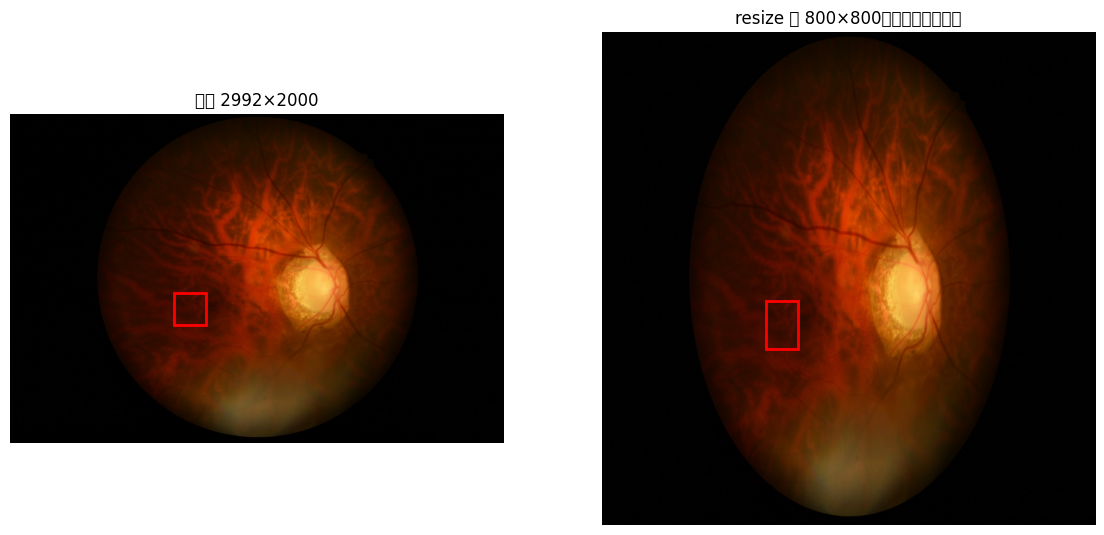

In [20]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 原图 vs resize 后对比
r = train_df[train_df.stem == "0049"].iloc[0]
img = Image.open(r.img)
img_resized = img.resize((800, 800))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img)
axes[0].set_title(f"原图 {r.W}×{r.H}")
axes[0].add_patch(plt.Rectangle((r.box[0], r.box[1]),
                                 r.box[2]-r.box[0], r.box[3]-r.box[1],
                                 fill=False, edgecolor='red', linewidth=2))
axes[0].axis('off')

axes[1].imshow(img_resized)
axes[1].set_title("resize 到 800×800（模型实际输入）")
sx, sy = 800/r.W, 800/r.H
axes[1].add_patch(plt.Rectangle((r.box[0]*sx, r.box[1]*sy),
                                 (r.box[2]-r.box[0])*sx, (r.box[3]-r.box[1])*sy,
                                 fill=False, edgecolor='red', linewidth=2))
axes[1].axis('off')
plt.show()

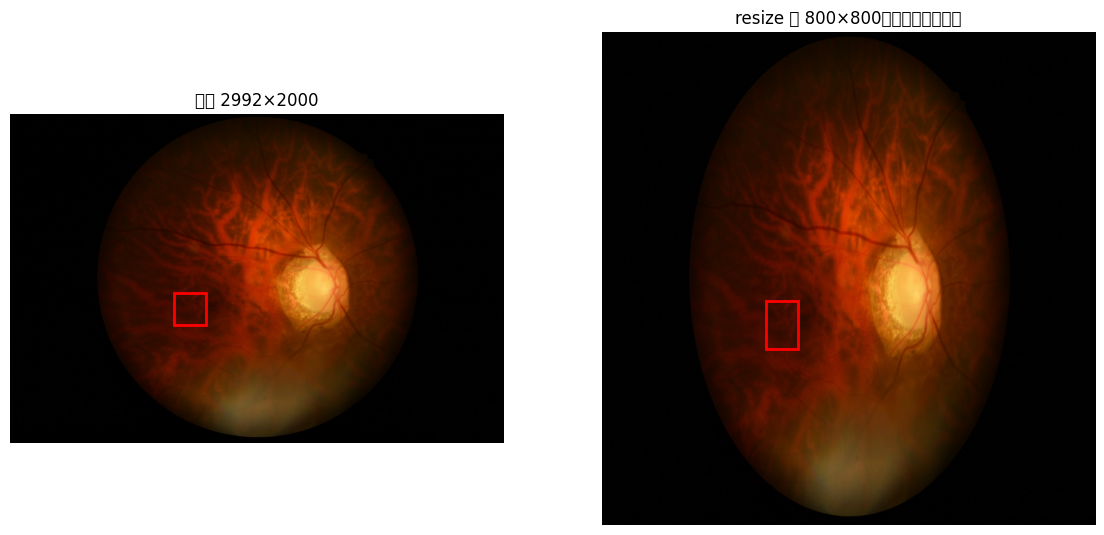

In [21]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 原图 vs resize 后对比
r = train_df[train_df.stem == "0049"].iloc[0]
img = Image.open(r.img)
img_resized = img.resize((800, 800))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img)
axes[0].set_title(f"原图 {r.W}×{r.H}")
axes[0].add_patch(plt.Rectangle((r.box[0], r.box[1]),
                                 r.box[2]-r.box[0], r.box[3]-r.box[1],
                                 fill=False, edgecolor='red', linewidth=2))
axes[0].axis('off')

axes[1].imshow(img_resized)
axes[1].set_title("resize 到 800×800（模型实际输入）")
sx, sy = 800/r.W, 800/r.H
axes[1].add_patch(plt.Rectangle((r.box[0]*sx, r.box[1]*sy),
                                 (r.box[2]-r.box[0])*sx, (r.box[3]-r.box[1])*sy,
                                 fill=False, edgecolor='red', linewidth=2))
axes[1].axis('off')
plt.show()

/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 32418 (\N{CJK UNIFIED IDEOGRAPH-7EA2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 26694 (\N{CJK UNIFIED IDEOGRAPH-6846}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 20869 (\N{CJK UNIFIED IDEOGRAPH-5185}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 37096 (\N{CJK UNIFIED IDEOGRAPH-90E8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 40644 (\N{CJK UNIFIED IDEOGRAPH-9EC4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/3897577444.py:17: UserWarning: Glyph 26001 (\N{CJK UNIFIED IDEOGRAPH-6591}) missing from

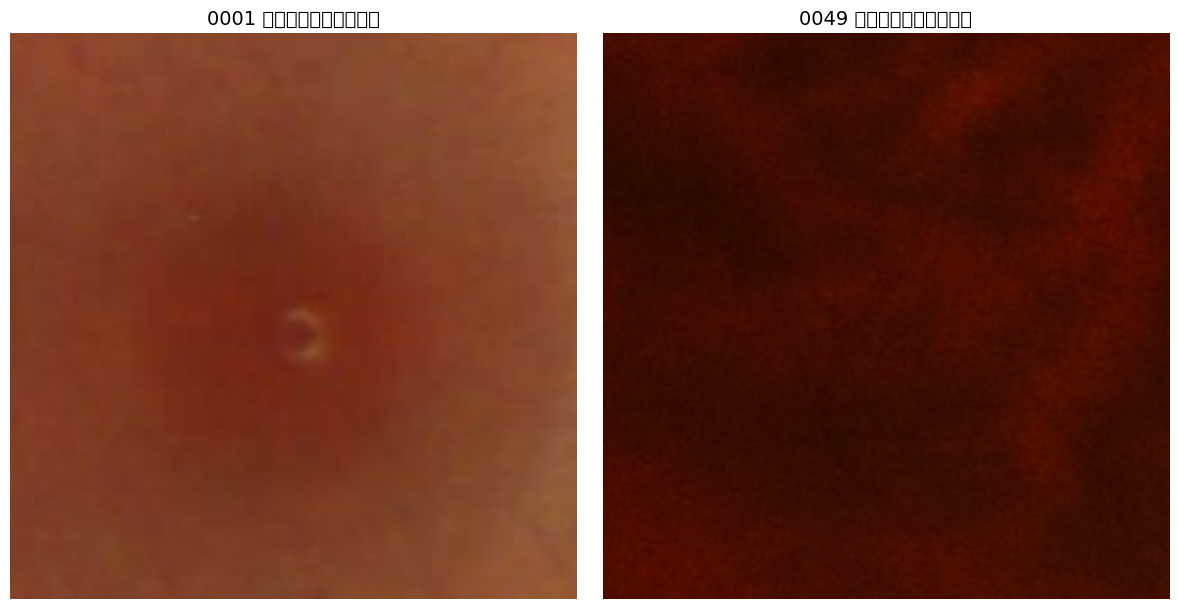

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, stem in zip(axes, ["0001", "0049"]):
    r = train_df[train_df.stem == stem].iloc[0]
    img = Image.open(r.img)
    # 只裁 bbox 内部
    crop = img.crop((r.box[0], r.box[1], r.box[2], r.box[3]))
    # 统一放大到 400x400，方便并排对比
    crop = crop.resize((400, 400))
    ax.imshow(crop)
    ax.set_title(f"{stem} 红框内部（黄斑区域）", fontsize=14)
    ax.axis('off')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25972 (\N{CJK UNIFIED IDEOGRAPH-6574}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io

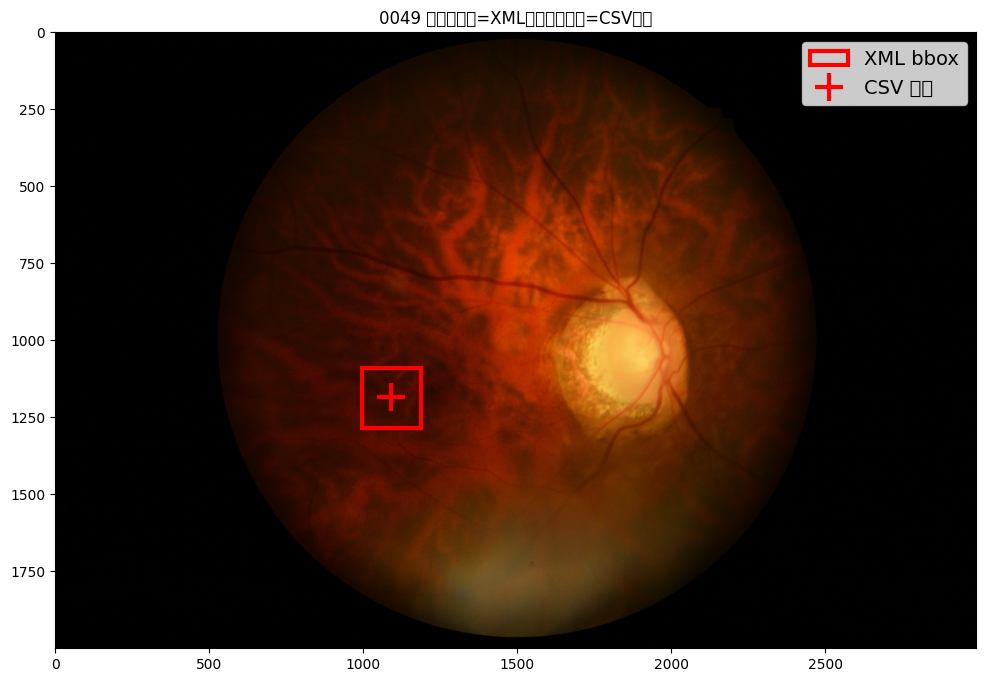

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

r = train_df[train_df.stem == "0049"].iloc[0]
img = Image.open(r.img)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(img)
# 红框（XML 标注）
ax.add_patch(patches.Rectangle(
    (r.box[0], r.box[1]), r.box[2]-r.box[0], r.box[3]-r.box[1],
    fill=False, edgecolor='red', linewidth=3, label='XML bbox'))
# 红点（CSV 真值）
ax.plot(r.fx, r.fy, 'r+', markersize=20, markeredgewidth=3, label='CSV 真值')
ax.legend(fontsize=14)
ax.set_title(f"0049 整图：红框=XML标注，红十字=CSV真值")
plt.show()